# 2. Style map: baseline

Active fighters (last UFC fight within 3 years) embedded from their 8 UFCStats career stats.
Pipeline: clean → log1p rates + standardise → PCA to 2D → k-means clusters → nearest neighbours.

Reusable code lives in `src/ufc_embedded/`; this notebook only runs and inspects it.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from ufc_embedded.data import PROCESSED_DIR, active_fighters, load_fighter_stats, load_fights
from ufc_embedded.style_map import STYLE_FEATURES, build_feature_table, fit_style_map, scale_features

pd.set_option("display.width", 200)

Matplotlib is building the font cache; this may take a moment.


## Data

The fighter stats file is a snapshot from **2024-02-17**, so `min_fights` is applied to UFC fights *up to that date*. Dropped: duplicate names (different people with the same name), all-zero stat rows (= no data on UFCStats), fewer than 3 fights.

In [2]:
fights = load_fights()
stats = load_fighter_stats()
active = active_fighters(fights, years=3)
table = build_feature_table(stats, active, min_fights=3)

print(f"active: {len(active)}  with stats: {active.index.isin(stats['name']).sum()}  after cleaning: {len(table)}")
table.head()

active: 879  with stats: 714  after cleaning: 514


,last_fight,n_fights,weight_class,n_fights_as_of,significant_strikes_landed_per_minute,significant_strikes_absorbed_per_minute,average_takedowns_landed_per_15_minutes,average_submissions_attempted_per_15_minutes,significant_striking_accuracy,significant_strike_defence,takedown_accuracy,takedown_defense
name,,,,,,,,,,,,
AJ Dobson,2024-03-23,4,Middleweight,3,4.38,5.25,1.82,0.3,47.0,47.0,75.0,64.0
AJ Fletcher,2023-09-23,4,Welterweight,4,3.36,4.61,1.54,0.9,49.0,46.0,35.0,33.0
Aaron Phillips,2023-04-15,4,Bantamweight,4,1.51,3.66,0.86,0.6,53.0,43.0,50.0,44.0
Abdul Razak Alhassan,2025-01-11,13,Middleweight,12,3.37,3.99,0.89,0.2,48.0,55.0,38.0,50.0
Abu Azaitar,2023-10-21,3,Middleweight,3,4.38,4.32,1.00,0.0,43.0,51.0,37.0,42.0


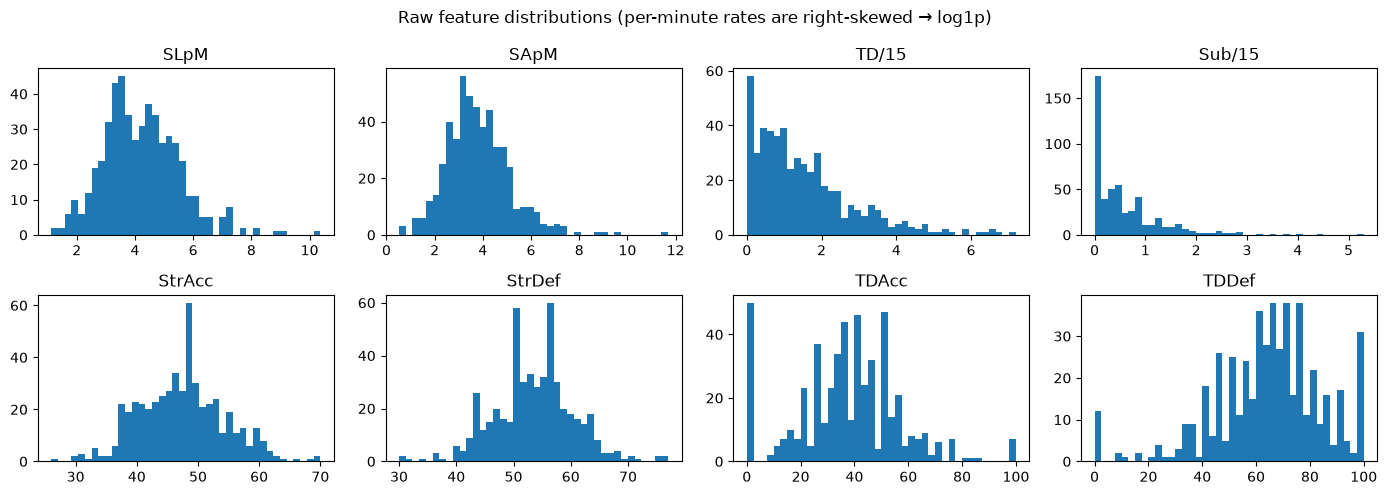

In [3]:
short = ["SLpM", "SApM", "TD/15", "Sub/15", "StrAcc", "StrDef", "TDAcc", "TDDef"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, col, s in zip(axes.flat, STYLE_FEATURES, short):
    ax.hist(table[col], bins=40)
    ax.set_title(s)
fig.suptitle("Raw feature distributions (per-minute rates are right-skewed → log1p)")
fig.tight_layout()

## How many clusters?

Silhouette is low for every k: fighting styles are a continuum, not well-separated blobs. k=2 scores best but is too coarse to be interesting; k=5 gives interpretable groups.

In [4]:
xs = scale_features(table)
pd.Series({k: silhouette_score(xs, KMeans(k, n_init=10, random_state=0).fit_predict(xs)) for k in range(2, 10)}, name="silhouette").round(3)

2    0.183
3    0.138
4    0.123
5    0.120
6    0.111
7    0.108
8    0.118
9    0.115
Name: silhouette, dtype: float64

In [5]:
sm = fit_style_map(table, n_clusters=5)
print("explained variance:", sm.pca.explained_variance_ratio_.round(3))
pd.DataFrame(sm.pca.components_.T, index=short, columns=["PC1", "PC2"]).round(2)

explained variance: [0.302 0.195]


,PC1,PC2
SLpM,-0.42,0.27
SApM,-0.45,-0.26
TD/15,0.50,0.13
Sub/15,0.41,-0.19
StrAcc,0.14,0.36
StrDef,-0.02,0.55
TDAcc,0.37,0.25
TDDef,-0.20,0.56


**Reading the axes**
- **PC1**: grappling (+ takedowns, subs, TD accuracy) vs. striking exchanges (+ strikes landed *and* absorbed). Right = wrestler/grappler.
- **PC2**: defence & efficiency (strike defence, TD defence, accuracy). Up = hard to hit / hard to take down.

## Clusters

Median stats per cluster; names are my interpretation.

In [6]:
profile = table[STYLE_FEATURES].groupby(sm.labels).median()
profile.columns = short
profile["n"] = pd.Series(sm.labels).value_counts().sort_index()
profile.round(2)

,SLpM,SApM,TD/15,Sub/15,StrAcc,StrDef,TDAcc,TDDef,n
0,5.19,4.68,0.05,0.0,47.0,53.0,9.0,68.0,91
1,3.67,2.55,3.38,0.9,53.0,57.0,50.0,75.0,72
2,3.70,3.44,1.09,0.2,42.0,57.0,37.5,69.0,138
3,3.04,3.20,1.90,1.1,45.0,50.0,37.0,42.0,89
4,5.04,4.23,1.08,0.3,50.0,53.0,44.0,68.0,124


In [7]:
cluster_names = {
    0: "Pure strikers",            # high output, ~no takedowns
    1: "Dominant wrestlers",       # most takedowns, lowest damage absorbed
    2: "Low-volume all-rounders",  # moderate everything, low output
    3: "Scrambly grapplers",       # sub hunters, poor TD defence
    4: "Volume mixers",            # high-output strikers who mix in takedowns
}
table = table.assign(x=sm.coords[:, 0], y=sm.coords[:, 1], cluster=sm.labels, style=[cluster_names[c] for c in sm.labels])
table["style"].value_counts()

style
Low-volume all-rounders    138
Volume mixers              124
Pure strikers               91
Scrambly grapplers          89
Dominant wrestlers          72
Name: count, dtype: int64

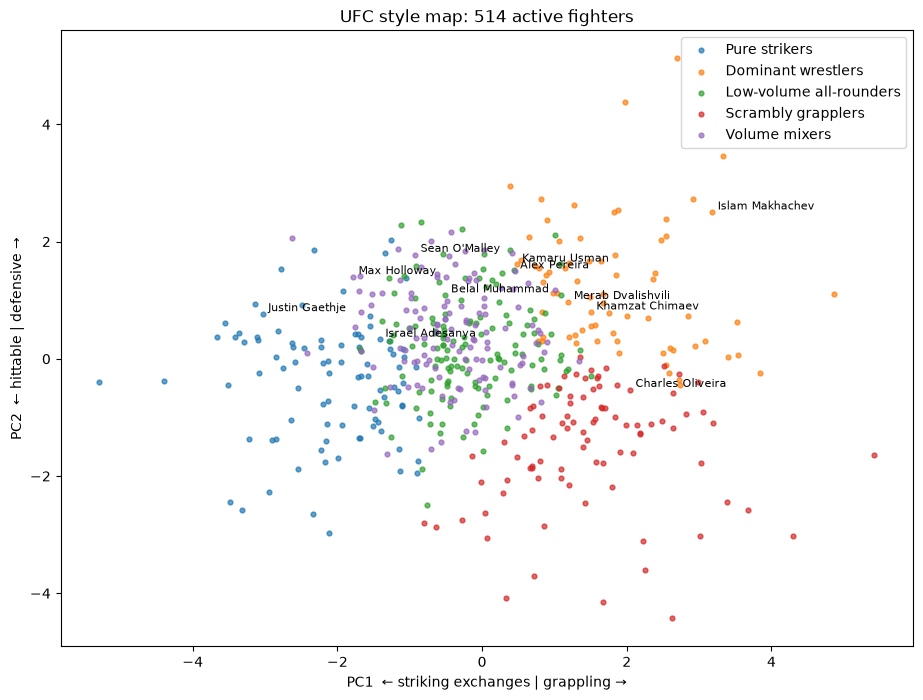

In [8]:
known = ["Islam Makhachev", "Alex Pereira", "Sean O'Malley", "Merab Dvalishvili", "Khamzat Chimaev",
         "Charles Oliveira", "Max Holloway", "Israel Adesanya", "Justin Gaethje", "Belal Muhammad", "Kamaru Usman"]

fig, ax = plt.subplots(figsize=(11, 8))
for c, name in cluster_names.items():
    sub = table[table["cluster"] == c]
    ax.scatter(sub["x"], sub["y"], s=12, alpha=0.7, label=name)
for n in known:
    ax.annotate(n, (table.loc[n, "x"], table.loc[n, "y"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("PC1  ← striking exchanges | grappling →")
ax.set_ylabel("PC2  ← hittable | defensive →")
ax.set_title(f"UFC style map: {len(table)} active fighters")
ax.legend()

## Similar fighters

In [9]:
pd.DataFrame({n: sm.neighbours(n, k=5).index for n in known[:6]})

,Islam Makhachev,Alex Pereira,Sean O'Malley,Merab Dvalishvili,Khamzat Chimaev,Charles Oliveira
0,Kanako Murata,Uros Medic,Alexander Volkanovski,Colby Covington,Preston Parsons,Deiveson Figueiredo
1,Caio Borralho,Johnny Walker,Chris Gutierrez,Movsar Evloev,Terrance McKinney,Brendan Allen
2,Montel Jackson,Carlos Ulberg,Manel Kape,Arman Tsarukyan,Anthony Hernandez,Andre Petroski
3,Jack Shore,Alexander Volkov,Ciryl Gane,Ricky Simon,Benoit Saint Denis,Matt Brown
4,Valentina Shevchenko,Mariya Agapova,Alexander Volkov,Piera Rodriguez,Jimmy Crute,Daniel Pineda


## Caveats / next steps
- Stats are frozen at Feb 2024 and are career averages (no style drift).
- Small-sample fighters still noisy → shrink toward weight-class mean.
- No strike target/position breakdown → own UFCStats scraper.
- Try UMAP for the 2D layout; colour by weight class.
- Women and men share the map; weight class isn't a feature.

In [10]:
out = PROCESSED_DIR / "style_map_v0.parquet"
out.parent.mkdir(parents=True, exist_ok=True)
table.to_parquet(out)
out

PosixPath('/Users/anar/Desktop/tum/26-winter/ufc_embedded/data/processed/style_map_v0.parquet')